# Movie Recommender (SVD Matrix Factorization)

**Question:** using past ratings, can we recommend movies a person is likely to enjoy, either for a specific user or based on a movie they already like?

**Data:** MovieLens "latest small" dataset: 100,836 ratings (0.5 to 5 stars) of 9,742 movies by 610 users.

**Approach:** train an SVD matrix factorization model with the Surprise library, evaluate it against a simple baseline, tune its settings with 5-fold cross-validation, then use it two ways: predicted ratings for a user's unseen movies, and similar movies based on the profiles the model learns for each movie.

**Key results:**
- The SVD model predicts held-out ratings within 0.881 stars (RMSE), 15.7% better than always guessing the average rating (1.045).
- Tuning improved the cross-validated RMSE from 0.873 to 0.861.
- Recommendations make sense: movies similar to *Toy Story* include *Aladdin*, *Toy Story 2* and *The Little Mermaid*; movies similar to *The Matrix* include *Die Hard*, the *Star Wars* films and *Inception*.

**Tools:** Python (pandas, NumPy, scikit-surprise)

**Context:** master's coursework (DSC630, Week 10), cleaned up and corrected for this portfolio.

## Method
Several kinds of recommender systems were compared: neighborhood collaborative filtering (k-NN), deep learning (neural collaborative filtering) and matrix factorization (SVD). SVD was chosen because it learns each user's and each movie's hidden preferences from the ratings alone, gives personalized recommendations, and scales to large data. It is the approach popularized by the Netflix Prize.

Sources used: the Surprise library documentation (https://surpriselib.com); Kaggle notebooks "MovieLens Recommendation System" (akashsdas) and "Recommendation System in Python" (evilspirit05); and *How To Build Your First Recommender System Using Python & MovieLens Dataset*, Analytics India Magazine (2019).

## 1. Load and check the data

In [1]:
# import required libraries
import warnings
import numpy as np
import pandas as pd
from surprise import SVD, Dataset, Reader, accuracy                       # matrix factorization recommender
from surprise.model_selection import train_test_split, cross_validate, GridSearchCV, KFold

warnings.filterwarnings('ignore', category=FutureWarning)

In [2]:
# MovieLens "latest small" dataset
df_movies = pd.read_csv('movies.csv')
df_ratings = pd.read_csv('ratings.csv')
print(f"{len(df_movies):,} movies, {len(df_ratings):,} ratings from {df_ratings['userId'].nunique():,} users")
print(f"Ratings range from {df_ratings['rating'].min()} to {df_ratings['rating'].max()}")
df_ratings.head()

9,742 movies, 100,836 ratings from 610 users
Ratings range from 0.5 to 5.0


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [3]:
# remove exact duplicates: one rating per user per movie (each movie should have many ratings from different users)
before = len(df_ratings)
df_ratings = df_ratings.drop_duplicates(subset=['userId', 'movieId']).dropna()
df_movies = df_movies.drop_duplicates(subset='movieId').dropna()
print(f'Duplicate user-movie ratings removed: {before - len(df_ratings)}')

ratings_per_movie = df_ratings.groupby('movieId').size()
print(f"Ratings per movie: median {ratings_per_movie.median():.0f}, "
      f"{(ratings_per_movie == 1).sum():,} movies have only one rating")

Duplicate user-movie ratings removed: 0
Ratings per movie: median 3, 3,446 movies have only one rating


## 2. Train and evaluate the SVD model

In [4]:
# Surprise needs to know the rating scale
reader = Reader(rating_scale=(0.5, 5))
data = Dataset.load_from_df(df_ratings[['userId', 'movieId', 'rating']], reader)

# 80/20 split, fixed random_state so results can be reproduced
training_set, testing_set = train_test_split(data, test_size=0.2, random_state=42)
svd = SVD(random_state=42)
svd.fit(training_set)
test_rmse = accuracy.rmse(svd.test(testing_set), verbose=False)

# baseline: predict every rating as the training set's average rating
global_mean = training_set.global_mean
baseline_rmse = np.sqrt(np.mean([(r - global_mean) ** 2 for (_, _, r) in testing_set]))
print(f'SVD test RMSE:      {test_rmse:.3f} stars')
print(f'Baseline test RMSE: {baseline_rmse:.3f} stars (always predict the average, {global_mean:.2f})')

SVD test RMSE:      0.881 stars
Baseline test RMSE: 1.045 stars (always predict the average, 3.50)


In [5]:
# 5-fold cross-validation for a more reliable estimate than one split
folds = KFold(n_splits=5, random_state=42, shuffle=True)   # fixed folds so results repeat
cv_results = cross_validate(SVD(random_state=42), data, measures=['RMSE'], cv=folds, verbose=False)
print('RMSE by fold:', np.round(cv_results['test_rmse'], 3))
print(f"Mean RMSE: {cv_results['test_rmse'].mean():.3f}")

RMSE by fold: [0.883 0.867 0.863 0.872 0.881]
Mean RMSE: 0.873


In [6]:
# try to improve the model by tuning its settings
param_grid = {
    'n_factors': [50, 100, 150],     # number of hidden preference factors
    'lr_all': [0.002, 0.005, 0.01],  # learning rate
    'reg_all': [0.02, 0.1, 0.2],     # regularization to reduce overfitting
    'random_state': [42],            # same starting point for every model
}
gs = GridSearchCV(SVD, param_grid, measures=['rmse'], cv=KFold(n_splits=5, random_state=42, shuffle=True), joblib_verbose=0)
gs.fit(data)
print(f"Best cross-validated RMSE: {gs.best_score['rmse']:.3f}")
print('Best settings:', gs.best_params['rmse'])

Best cross-validated RMSE: 0.861
Best settings: {'n_factors': 150, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}


In [7]:
# retrain on all ratings with the best settings, for making recommendations
best_svd = SVD(**gs.best_params['rmse'])   # best_params already includes random_state=42
full_trainset = data.build_full_trainset()
best_svd.fit(full_trainset);

## 3. Recommendations for a user
For a given user, the model predicts a rating for every movie the user has not rated yet and returns the highest. Movies with fewer than 20 ratings are left out, because the model knows too little about them to recommend them confidently.

In [8]:
MIN_RATINGS = 20
popular_movies = ratings_per_movie[ratings_per_movie >= MIN_RATINGS].index

def get_movie_recs(user_id, num_recommendations=10):
    seen = set(df_ratings.loc[df_ratings['userId'] == user_id, 'movieId'])
    candidates = [m for m in popular_movies if m not in seen]
    predictions = sorted(((m, best_svd.predict(user_id, m).est) for m in candidates), key=lambda x: x[1], reverse=True)
    top = pd.DataFrame(predictions[:num_recommendations], columns=['movieId', 'predicted_rating'])
    return top.merge(df_movies[['movieId', 'title']], on='movieId')[['title', 'predicted_rating']].round(2)

# example: user 1 (the original version asked for a user ID with input(); a fixed example keeps the notebook runnable)
user_id = 1
print(f"User {user_id} has rated {(df_ratings['userId'] == user_id).sum()} movies. Their top-rated ones include:")
print(df_ratings[df_ratings['userId'] == user_id].merge(df_movies, on='movieId').sort_values('rating', ascending=False)['title'].head(5).to_string(index=False))
get_movie_recs(user_id)

User 1 has rated 232 movies. Their top-rated ones include:
             M*A*S*H (a.k.a. MASH) (1970)
                         Excalibur (1981)
Indiana Jones and the Last Crusade (1989)
              Pink Floyd: The Wall (1982)
             From Russia with Love (1963)


,title,predicted_rating
0,"Shawshank Redemption, The (1994)",5.00
1,Dr. Strangelove or: How I Learned to Stop Worr...,5.00
2,"Godfather, The (1972)",5.00
3,"Streetcar Named Desire, A (1951)",5.00
4,Lawrence of Arabia (1962),5.00
5,Ghost in the Shell (Kôkaku kidôtai) (1995),4.99
6,There Will Be Blood (2007),4.99
7,"Philadelphia Story, The (1940)",4.99
8,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.98
9,Casablanca (1942),4.97


## 4. Movies similar to one you like
The assignment asks for recommendations based on a movie the user likes. SVD also learns a profile (a set of hidden factors) for every movie, so movies with similar profiles are ones that the same people tend to rate the same way. Cosine similarity between those profiles finds the closest matches.

In [9]:
# movie profiles learned by the model, one row per movie
inner_ids = [best_svd.trainset.to_inner_iid(m) for m in popular_movies]
item_factors = best_svd.qi[inner_ids]
item_factors = item_factors / np.linalg.norm(item_factors, axis=1, keepdims=True)
titles = df_movies.set_index('movieId').loc[popular_movies, 'title'].values

def similar_movies(title, num_recommendations=10):
    matches = np.where(titles == title)[0]
    if len(matches) == 0:
        return f"'{title}' was not found (or has fewer than {MIN_RATINGS} ratings)."
    sims = item_factors @ item_factors[matches[0]]
    order = [i for i in np.argsort(-sims) if i != matches[0]][:num_recommendations]
    return pd.DataFrame({'title': titles[order], 'similarity': sims[order].round(3)})

similar_movies('Toy Story (1995)')

,title,similarity
0,Wallace & Gromit: The Wrong Trousers (1993),0.488
1,Aladdin (1992),0.484
2,Back to the Future (1985),0.388
3,E.T. the Extra-Terrestrial (1982),0.388
4,101 Dalmatians (1996),0.368
5,Toy Story 2 (1999),0.348
6,"Little Mermaid, The (1989)",0.337
7,Ghostbusters (a.k.a. Ghost Busters) (1984),0.324
8,Babe (1995),0.322
9,It's a Wonderful Life (1946),0.318


In [10]:
similar_movies('Matrix, The (1999)')

,title,similarity
0,Die Hard (1988),0.542
1,Star Wars: Episode V - The Empire Strikes Back...,0.378
2,Star Wars: Episode VI - Return of the Jedi (1983),0.353
3,Who Framed Roger Rabbit? (1988),0.349
4,Léon: The Professional (a.k.a. The Professiona...,0.349
5,Seven (a.k.a. Se7en) (1995),0.342
6,Star Wars: Episode IV - A New Hope (1977),0.334
7,War of the Worlds (2005),0.334
8,"Dark Knight Rises, The (2012)",0.334
9,Inception (2010),0.332


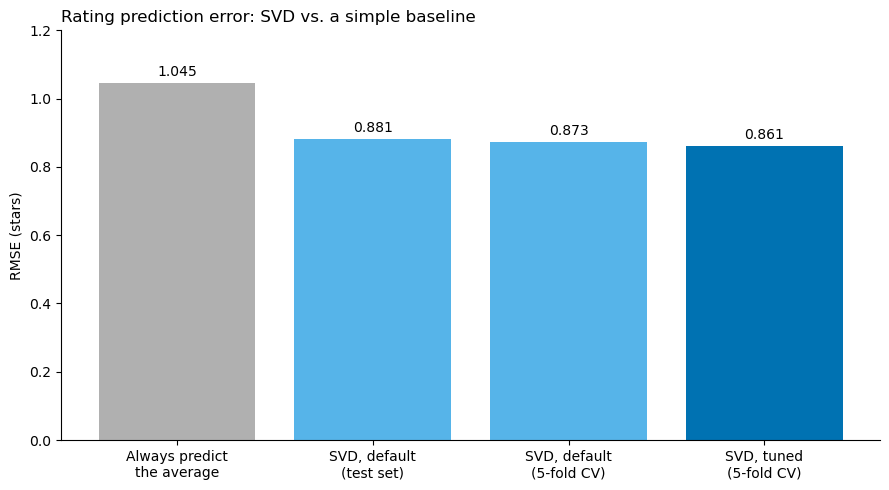

In [11]:
# summary chart: prediction error for each approach (lower is better)
import matplotlib.pyplot as plt
labels = ['Always predict\nthe average', 'SVD, default\n(test set)', 'SVD, default\n(5-fold CV)', 'SVD, tuned\n(5-fold CV)']
values = [baseline_rmse, test_rmse, cv_results['test_rmse'].mean(), gs.best_score['rmse']]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, values, color=['#b0b0b0', '#56B4E9', '#56B4E9', '#0072B2'])
ax.bar_label(bars, labels=[f'{v:.3f}' for v in values], padding=3)
ax.set_ylabel('RMSE (stars)'); ax.set_ylim(0, 1.2)
ax.set_title('Rating prediction error: SVD vs. a simple baseline', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Findings
- **The model learns real preferences.** On 20% of ratings held back for testing, SVD's typical error is 0.881 stars, compared with 1.045 for always predicting the average (3.50). Five-fold cross-validation gives a similar 0.873, and tuning (150 factors, learning rate 0.01, regularization 0.1) lowers it to 0.861.
- **Movie-to-movie recommendations are intuitive.** The model was never told any genres, yet movies similar to *Toy Story* are family and animated films (*Wallace & Gromit*, *Aladdin*, *Toy Story 2*), and movies similar to *The Matrix* are action and science fiction (*Die Hard*, *Star Wars*, *Inception*). It learned these groupings from rating patterns alone.
- **User recommendations favor acclaimed films.** User 1's list is led by classics such as *The Shawshank Redemption*, *The Godfather* and *Casablanca*. User 1 rates generously (average 4.37 vs. 3.50 overall; 53.4% of their ratings are 5 stars), so many predictions reach the 5-star ceiling and the list is effectively a tie at the top.
- **Limitations and next steps:**
    - Ratings are sparse: the median movie has only 3 ratings, and 3,446 movies have just one. The recommendations are limited to movies with at least 20 ratings for that reason.
    - New users and new movies cannot be recommended until they have ratings (the "cold start" problem); adding genres or tags would help.
    - RMSE measures rating accuracy, not whether people would actually watch the recommendations; ranking metrics such as precision at 10 would be a better test.

**Correction note:** the original version removed duplicate rows by movie ID, which kept only one rating per movie and threw away 91,112 of the 100,836 ratings. The model was trained on that reduced data, so its recommendations were close to random, and the RMSE values written in its comments (0.86 to 0.88) did not match its own output (0.94). This version keeps every rating, removes only true duplicates (the same user rating the same movie twice, of which there are none), fixes the random seed so results repeat, and replaces the typed `input()` prompts with a function call so the notebook runs from start to finish. The movie-based recommendations in section 4 are new. The original notebook is in `earlier_versions/`.